# Problem 8.1: Titanic: who survived?

Build a classifier for survival from titanic_train.csv using a model you know (kNN or a shallow decision tree). Because the separate test file has no answer column, make your OWN honest test set: split titanic_train.csv 70/30 with train_test_split, exactly as in Lab 1. You will need light preparation: pick 2–4 numeric-ready features (class, age, sex encoded as 0/1, fare), and handle the 177 missing ages (Module 3 skills return). Optional stretch: predict on titanic_test.csv afterward, like a real Kaggle submission, knowing you cannot score it yourself.

In [5]:
import pandas as pd

df = pd.read_csv("titanic_train.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Picking 4 numeric features

In [6]:
X = df[["Pclass", "Sex", "Age", "Fare"]].copy()
y=df["Survived"]

### Turn sex into numerical values
male = 0 female = 1

In [7]:
X["Sex"] = X["Sex"].map({"male":0, "female":1})

### Replace 177 missing ages with median age

In [8]:
X["Age"] = X["Age"].fillna(X["Age"].median())

### create a 70/30 split

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Create shallow classifier

[Text(0.5, 0.875, 'Sex <= 0.5\ngini = 0.467\nsamples = 623\nvalue = [392, 231]\nclass = Died'),
 Text(0.25, 0.625, 'Age <= 6.5\ngini = 0.302\nsamples = 410\nvalue = [334, 76]\nclass = Died'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'Fare <= 27.562\ngini = 0.42\nsamples = 20\nvalue = [6, 14]\nclass = Survived'),
 Text(0.0625, 0.125, 'gini = 0.0\nsamples = 10\nvalue = [0, 10]\nclass = Survived'),
 Text(0.1875, 0.125, 'gini = 0.48\nsamples = 10\nvalue = [6, 4]\nclass = Died'),
 Text(0.375, 0.375, 'Fare <= 52.277\ngini = 0.267\nsamples = 390\nvalue = [328.0, 62.0]\nclass = Died'),
 Text(0.3125, 0.125, 'gini = 0.227\nsamples = 344\nvalue = [299, 45]\nclass = Died'),
 Text(0.4375, 0.125, 'gini = 0.466\nsamples = 46\nvalue = [29, 17]\nclass = Died'),
 Text(0.75, 0.625, 'Pclass <= 2.5\ngini = 0.396\nsamples = 213\nvalue = [58, 155]\nclass = Survived'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'Age <= 2.5\ngini = 0.07\nsamples = 110\nvalue = [4, 106]\nclass = Survived'),
 Te

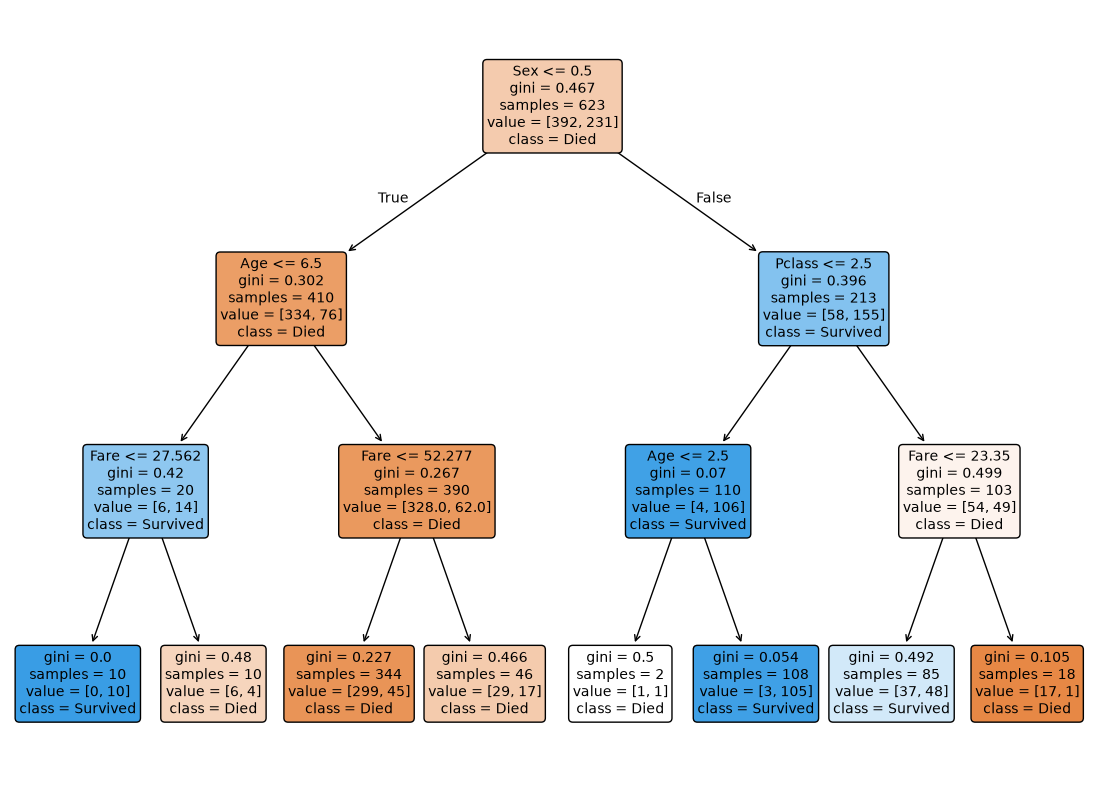

In [17]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

classifier = DecisionTreeClassifier(max_depth=3, random_state=42)
classifier.fit(X_train, y_train)
plt.figure(figsize=(14, 10))
plot_tree(classifier,
          feature_names=["Pclass", "Sex", "Age", "Fare"],
          class_names=["Died", "Survived"],
          filled = True,
          rounded=True,
         fontsize=10)

# score the model

In [22]:
train_score = classifier.score(X_train, y_train)
test_score = classifier.score(X_test, y_test)

print(f"{"Train Score:"} | {"Test Score:"}")
print("-"*30)
print(f"{train_score:<13.4f}|{test_score:4f}")

Train Score: | Test Score:
------------------------------
0.8266       |0.805970


### Check which passengers model gets wrong most

In [24]:
#generating predictions 
y_pred = classifier.predict(X_test)
# put test, actual answers, and predictions together
results = X_test.copy()
results['Actual'] = y_test
results['Predicted'] = y_pred

# filter for rows the model got wrong
errors= results[results["Actual"] != results["Predicted"]]

#group errors by sex and pclass to see what is wrong the most
print(errors.groupby(["Sex", "Pclass"]).size())


Sex  Pclass
0    1         20
     2          2
     3         12
1    2          5
     3         13
dtype: int64


Based on the test, the passengers that the model got wrong most times was 1st class males, it thought they dies when they survived, and 3rd class females, it thought they survived when they died. It seems like the model relied heavily on whether or not the passenger was male or female to determine survival rate, when class also played a big part.

#### Github URL
https://github.com/Alexisyarbs/cs82a-portfolio/blob/main/module%207/module7_lab3.ipynb